# Predicting Machine Failure with AI4I 2020

This project uses machine operating measurements to classify whether a datapoint is labeled as a machine failure. I compare Logistic Regression and Random Forest to see how well each model catches failures.

The data comes from the simulated AI4I 2020 Predictive Maintenance dataset, available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset).

## Notebook sections
1. Load the data
2. Explore the data
3. Choose features and split the data
4. Train a Logistic Regression baseline
5. Random Forest
6. Compare the models
7. Inspect feature importance
8. Summarize findings and limitations


## 1. Load the data

The CSV is in the project folder beside this notebook. I load it into a Pandas DataFrame and check a few rows to make sure it looks right.

In [35]:
import pandas as pd
df = pd.read_csv("ai4i2020.csv")

## 2. Explore the data

I checked the dataset size, column types, missing values, and the number of failure and no-failure rows. This gives me a basic understanding of the data before choosing model inputs.

In [36]:
print(df.head())


   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

In [37]:
print(df.tail())

        UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  \
9995                    1604         29.5               14                0   
9996                    1632         31.8               17                0   
9997                    1645         33.4               22                0   
9998                    1408         48.5               25                0   
9999                    1500         40.2               30                0   

      TWF  HDF  PWF  OSF  RNF  
9995    0    0    0    0    0 

In [38]:
print("Shape:", df.shape)

df.info()

Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), 

In [39]:
print("\nMissing Values:\n", df.isna().sum())

print("\nMachine Failures Count:\n", df['Machine failure'].value_counts())


print("Machine failure percentage:\n", df['Machine failure'].value_counts(normalize=True) * 100)




Missing Values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Machine Failures Count:
 Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure percentage:
 Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


There are 10,000 rows and no missing values. Of these, 339 (3.39%) are labeled as failures. Since failures are much less common than non-failures, accuracy by itself could be misleading. I will also compare precision, recall, and F1 for the failure class.

## 3. Choose features and split the data

The target is `Machine failure`. I use product `Type` and five operating measurements as inputs: air temperature, process temperature, rotational speed, torque, and tool wear.

I leave out `UDI` and `Product ID` because they are identifiers, not measurements of machine operation. I also leave out `TWF`, `HDF`, `PWF`, `OSF`, and `RNF`. These columns describe the failure modes that make up `Machine failure`, so using them as inputs would give the model information about the answer.

I split the rows into training and test sets, keeping 20% for the final test. Stratifying the split keeps the failure rate similar in both sets. I use this same split for both models.

In [40]:
from sklearn.model_selection import train_test_split

# Convert the product category into numeric indicator columns.

df = pd.get_dummies(df, columns=['Type'], drop_first=True)

# Keep only the selected measurements and product-type indicators.

x = df.drop(['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)

y = df['Machine failure']

train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)


## 4. Logistic Regression baseline

I start with Logistic Regression as a baseline. Its pipeline scales the measurements before fitting the model. For five-fold cross-validation, the training data is divided into five parts. Each round trains on four parts and evaluates on the remaining part. The separate test set is used for the final evaluation.

5-fold cross-validation results (training data):
Accuracy: 0.970 +/- 0.001
Precision: 0.757 +/- 0.109
Recall: 0.196 +/- 0.031
F1: 0.307 +/- 0.031

Held-out test results:
              precision    recall  f1-score   support

  No failure       0.97      1.00      0.98      1932
     Failure       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



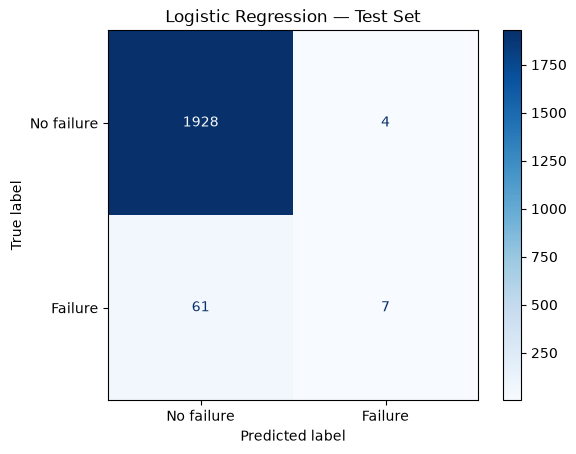

In [41]:
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Standardize measurements for Logistic Regression.
# Keeping preprocessing and the model in a pipeline ensures scaling is
# fitted separately within each cross-validation fold.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_results = cross_validate(
    logistic_model,
    train_x,
    train_y,
    cv=cv,
    scoring=scoring
)

print("5-fold cross-validation results (training data):")
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.capitalize()}: {scores.mean():.3f} +/- {scores.std():.3f}")

# Fit on all training data, then evaluate once on the held-out test data.
logistic_model.fit(train_x, train_y)
test_predictions = logistic_model.predict(test_x)

print("\nHeld-out test results:")
print(
    classification_report(
        test_y,
        test_predictions,
        target_names=["No failure", "Failure"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    test_y,
    test_predictions,
    display_labels=["No failure", "Failure"],
    cmap="Blues"
)
plt.title("Logistic Regression — Test Set")
plt.show()

## 5. Random Forest

I also train a Random Forest, which can learn more complex patterns in the measurements. I evaluate it with the same cross-validation setup and test set as Logistic Regression. Random Forest does not need feature scaling.

5-fold cross-validation results for Random Forest (training data):
Accuracy: 0.981 +/- 0.002
Precision: 0.883 +/- 0.029
Recall: 0.521 +/- 0.067
F1: 0.652 +/- 0.052

Random Forest held-out test results:
              precision    recall  f1-score   support

  No failure       0.99      1.00      0.99      1932
     Failure       0.93      0.59      0.72        68

    accuracy                           0.98      2000
   macro avg       0.96      0.79      0.86      2000
weighted avg       0.98      0.98      0.98      2000



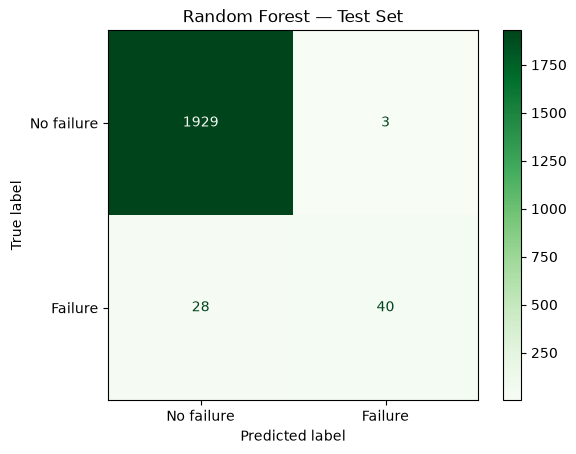

In [42]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest does not need feature scaling, so it can be used directly.
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Use the same folds and metrics as Logistic Regression for comparison.
rf_cv_results = cross_validate(
    random_forest_model,
    train_x,
    train_y,
    cv=cv,
    scoring=scoring
)

print("5-fold cross-validation results for Random Forest (training data):")
for metric in scoring:
    scores = rf_cv_results[f"test_{metric}"]
    print(f"{metric.capitalize()}: {scores.mean():.3f} +/- {scores.std():.3f}")

# Fit on all training data, then evaluate on the same held-out test set.
random_forest_model.fit(train_x, train_y)
rf_test_predictions = random_forest_model.predict(test_x)

print("\nRandom Forest held-out test results:")
print(
    classification_report(
        test_y,
        rf_test_predictions,
        target_names=["No failure", "Failure"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    test_y,
    rf_test_predictions,
    display_labels=["No failure", "Failure"],
    cmap="Greens"
)
plt.title("Random Forest — Test Set")
plt.show()

## 6. Compare the models

The table compares each model's average failure recall and F1 across the training folds, along with precision, recall, F1, and accuracy on the held-out test set. I pay particular attention to failure recall and F1 because failures are uncommon.

In [44]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Compare failure-class metrics from cross-validation and the held-out test set.
model_comparison = pd.DataFrame({
    "Logistic Regression": {
        "CV failure recall": cv_results["test_recall"].mean(),
        "CV failure F1": cv_results["test_f1"].mean(),
        "Test failure precision": precision_score(test_y, test_predictions, zero_division=0),
        "Test failure recall": recall_score(test_y, test_predictions, zero_division=0),
        "Test failure F1": f1_score(test_y, test_predictions, zero_division=0),
        "Test accuracy": accuracy_score(test_y, test_predictions),
    },
    "Random Forest": {
        "CV failure recall": rf_cv_results["test_recall"].mean(),
        "CV failure F1": rf_cv_results["test_f1"].mean(),
        "Test failure precision": precision_score(test_y, rf_test_predictions, zero_division=0),
        "Test failure recall": recall_score(test_y, rf_test_predictions, zero_division=0),
        "Test failure F1": f1_score(test_y, rf_test_predictions, zero_division=0),
        "Test accuracy": accuracy_score(test_y, rf_test_predictions),
    },
}).T

display(model_comparison.round(3))

,CV failure recall,CV failure F1,Test failure precision,Test failure recall,Test failure F1,Test accuracy
Logistic Regression,0.196,0.307,0.636,0.103,0.177,0.968
Random Forest,0.521,0.652,0.930,0.588,0.721,0.984


## 7. Feature importance

I use permutation importance to see how much each input matters to the fitted Random Forest. It shuffles one feature at a time and measures the change in failure-class F1. The mean is the average change over 20 shuffles, and the standard deviation shows how much the result varied between shuffles. This describes how the model uses these features; it does not show that a feature causes failure.

,feature,importance_mean,importance_std
3,Torque [Nm],0.421,0.027
2,Rotational speed [rpm],0.360,0.024
0,Air temperature [K],0.279,0.033
4,Tool wear [min],0.183,0.024
1,Process temperature [K],0.102,0.029
5,Type_L,0.020,0.023
6,Type_M,0.001,0.016


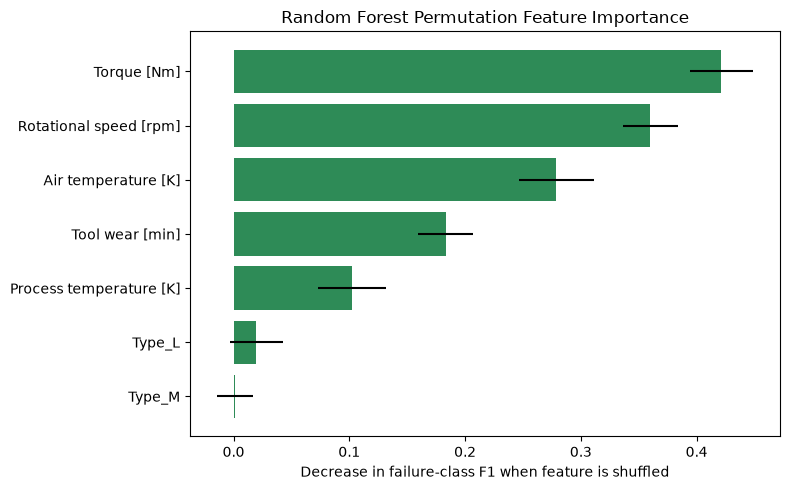

In [45]:
from sklearn.inspection import permutation_importance

# Measure how much the held-out failure F1 changes when each feature is shuffled.
importance = permutation_importance(
    random_forest_model,
    test_x,
    test_y,
    scoring="f1",
    n_repeats=20,
    random_state=42
)

importance_df = pd.DataFrame({
    "feature": test_x.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean")

display(importance_df.sort_values("importance_mean", ascending=False).round(3))

plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["feature"],
    importance_df["importance_mean"],
    xerr=importance_df["importance_std"],
    color="seagreen"
)
plt.xlabel("Decrease in failure-class F1 when feature is shuffled")
plt.title("Random Forest Permutation Feature Importance")
plt.tight_layout()
plt.show()

## 8. Findings and limitations

### Model results

Across the five training folds, Random Forest had higher failure recall (0.521) and F1 (0.652) than Logistic Regression (0.196 recall and 0.307 F1). On the held-out test set, Random Forest's failure recall was 0.59, so it caught about 40 of 68 failures and missed about 28. Its failure precision was 0.93, meaning most rows it flagged as failures were failures. The 0.98 accuracy is less informative because most test rows are non-failures.

### Feature importance

Torque had the largest mean importance (0.421, standard deviation 0.027), followed by rotational speed (0.360, 0.024), air temperature (0.279, 0.033), tool wear (0.183, 0.024), and process temperature (0.102, 0.029). The `Type_L` and `Type_M` indicators were close to zero in this run. For torque, shuffling its values lowered failure-class F1 by about 0.421 on average. This is a change in the F1 score on a 0-to-1 scale, not a percent increase in failure risk. The standard deviation shows variation between shuffles; it is not a confidence interval.

These values describe this Random Forest on this test set; they do not prove that torque causes failures or works independently of the other inputs. The dataset description says that some generated failure rules use combinations of measurements, such as torque and rotational speed for power failure. That context helps explain why both may matter, but the importance plot is not a causal analysis.

### Limitations

This is a simulated dataset, and the test results come from one train/test split. The Random Forest's cross-validation and test scores are fairly close, but that alone does not prove the model is free of overfitting. Results can vary with a different split, and the model still misses some failures.